In [33]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

In [20]:
df = pd.read_csv('dataset.csv')
df.head()

,title,company,label,word_count,char_count,unpaid_signal,equity_mention,remote_claim,onsite_required,hybrid,...,experience_years_min,experience_years_max,tech_count,tech_terms,stack_overlap_count,stack_overlap_ratio,hype_count,emoji_count,exclamation_count,evidence_json
0,Back End Developer (Founding Backend / AI Engi...,Zavvis,ignore,391,2946,0,1,1,0,0,...,NaN,NaN,12,azure|django|docker|fastapi|flask|langchain|la...,6,0.50,1,0,0,"{""equity_mention"": [""Equity"", ""equity""], ""remo..."
1,Software Engineer Intern (Path to Full-Time),Gattai,verify,236,1698,0,0,1,0,0,...,NaN,NaN,11,git|javascript|llm|next.js|node.js|nosql|pytho...,4,0.36,1,0,0,"{""remote_claim"": [""Remote"", ""remote"", ""100% Re..."
2,AI Intern - Digital Diplomacy,DiploTools,ignore,217,1634,1,0,0,0,1,...,NaN,NaN,9,docker|kubernetes|llm|next.js|nosql|python|rag...,3,0.33,0,0,0,"{""unpaid_signal"": [""unpaid""], ""hybrid"": [""hybr..."
3,"Atlantbh Internship (Software Development, QA,...",Atlantbh,ignore,218,1607,0,0,1,0,0,...,NaN,NaN,14,angular|ci/cd|docker|git|java|javascript|kuber...,6,0.43,1,0,1,"{""remote_claim"": [""remotely""], ""occasional_vis..."
4,Python Developer Intern | Entry Level | Fresher,Crossing Infotech,ignore,182,1414,0,0,1,0,0,...,NaN,NaN,10,django|fastapi|flask|git|javascript|mysql|post...,7,0.70,0,0,0,"{""remote_claim"": [""Remote"", ""Remote"", ""remote""..."


In [21]:
X = df.drop(columns=["title", "company", "label", "evidence_json", "tech_terms", "deadline"])
y = df['label']

In [22]:
X = pd.get_dummies(X, columns=["salary_currency", "salary_period"], dtype=int)
X = X.fillna(-1)
X

,word_count,char_count,unpaid_signal,equity_mention,remote_claim,onsite_required,hybrid,occasional_visits,location_restriction,work_auth_required,...,stack_overlap_ratio,hype_count,emoji_count,exclamation_count,salary_currency_GBP,salary_currency_INR,salary_currency_USD,salary_period_hour,salary_period_month,salary_period_year
0,391,2946,0,1,1,0,0,0,0,0,...,0.50,1,0,0,0,0,0,0,0,0
1,236,1698,0,0,1,0,0,0,0,0,...,0.36,1,0,0,0,0,0,0,0,0
2,217,1634,1,0,0,0,1,0,0,0,...,0.33,0,0,0,0,0,0,0,0,0
3,218,1607,0,0,1,0,0,1,0,0,...,0.43,1,0,1,0,0,0,0,0,0
4,182,1414,0,0,1,0,0,0,0,0,...,0.70,0,0,0,0,1,0,0,1,0
5,334,1987,0,0,1,0,0,0,0,0,...,0.40,5,4,0,0,0,0,0,0,0
6,175,1420,0,0,1,0,0,0,0,0,...,1.00,0,0,0,0,1,0,0,1,0
7,186,1303,0,0,1,0,0,0,0,0,...,0.00,2,0,0,0,0,0,0,0,0
8,239,1767,0,0,1,0,0,0,0,0,...,0.40,1,0,1,0,0,0,0,0,0
9,258,1794,0,0,1,0,0,0,0,0,...,0.17,1,0,0,0,0,1,1,0,0


In [26]:
print('X shape:', X.shape)
print('y shape:', y.shape)

X shape: (20, 43)
y shape: (20,)


In [29]:
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [30]:
print('x train shape:', x_train.shape)
print('y train shape:', y_train.shape)

x train shape: (16, 43)
y train shape: (16,)


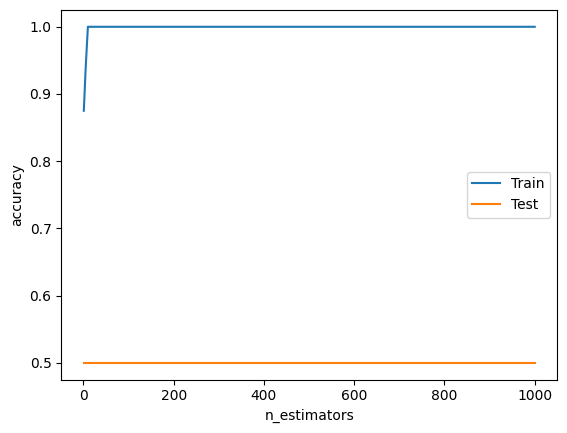

In [35]:
n_estimators = [1,5,10,20,50,100, 200, 500, 1000]
train_accuracies = []
test_accuracies = []
for n_estimator in n_estimators:
    model = RandomForestClassifier(n_jobs=-1,random_state=42,n_estimators=n_estimator)
    model.fit(x_train, y_train)
    y_pred_train = model.predict(x_train)
    y_pred_test = model.predict(x_test)
    train_accuracy = accuracy_score(y_train, y_pred_train)
    test_accuracy = accuracy_score(y_test, y_pred_test)
    train_accuracies.append(train_accuracy)
    test_accuracies.append(test_accuracy)
plt.plot(n_estimators, train_accuracies, label="Train")
plt.plot(n_estimators, test_accuracies, label="Test")

plt.legend()
plt.xlabel("n_estimators")
plt.ylabel("accuracy")
plt.show()

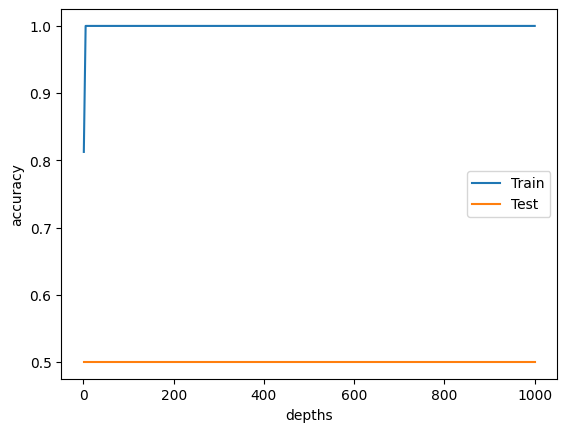

In [36]:
depths = [1,5,10,20,50,100, 200, 500, 1000]
train_accuracies = []
test_accuracies = []
for depth in depths:
    model = RandomForestClassifier(n_jobs=-1,random_state=42, max_depth=depth)
    model.fit(x_train, y_train)
    y_pred_train = model.predict(x_train)
    y_pred_test = model.predict(x_test)
    train_accuracy = accuracy_score(y_train, y_pred_train)
    test_accuracy = accuracy_score(y_test, y_pred_test)
    train_accuracies.append(train_accuracy)
    test_accuracies.append(test_accuracy)
plt.plot(depths, train_accuracies, label="Train")
plt.plot(depths, test_accuracies, label="Test")

plt.legend()
plt.xlabel("depths")
plt.ylabel("accuracy")
plt.show()

In [38]:
model = RandomForestClassifier(n_jobs=-1, random_state=42, max_depth=5, n_estimators=10)

model.fit(x_train, y_train)

y_pred_train = model.predict(x_train)
y_pred_test = model.predict(x_test)

train_accuracy = accuracy_score(y_train, y_pred_train)
test_accuracy = accuracy_score(y_test, y_pred_test)

print(f"Train Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy:  {test_accuracy:.4f}")


Train Accuracy: 1.0000
Test Accuracy:  0.5000
